# EDA (Exploratory Data Analysis)

This notebook contains the EDA performed for Exercise 3 in TDT4225

In [1]:
# Imports
import ast
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## 1 Inspect the dataset files
Understand what data is available before analyzing it.

In [3]:
DATA_DIR = Path("movies_datasets")

csv_files = [
    "credits.csv",
    "keywords.csv",
    "links_small.csv",
    "links.csv",
    "movies_metadata.csv",
    "ratings_small.csv",
    "ratings.csv"
]

file_summary = []

for filename in csv_files:
    file_path = DATA_DIR / filename

    if not file_path.exists():
        print(f"File not found: {filename}")
        continue

    columns = pd.read_csv(file_path, nrows=0).columns.tolist()

    row_count = sum(
        len(chunk)
        for chunk in pd.read_csv(
            file_path,
            chunksize=100_000,
            low_memory=False
        )
    )

    file_summary.append({
        "File": filename,
        "Rows": row_count,
        "Columns": len(columns)
    })

display(pd.DataFrame(file_summary))

,File,Rows,Columns
0,credits.csv,45476,3
1,keywords.csv,46419,2
2,links_small.csv,9125,3
3,links.csv,45843,3
4,movies_metadata.csv,45466,24
5,ratings_small.csv,100004,4
6,ratings.csv,26024289,4


In [3]:
for filename in csv_files:
    file_path = DATA_DIR / filename

    sample = pd.read_csv(file_path, nrows=5)
    
    print(f"FILE: {filename}")
    
    print("\nColumn names:")
    print(sample.columns.tolist())

    print("\nData types:")
    print(sample.dtypes)

    print("\nFirst 5 records:")
    display(sample)

FILE: credits.csv

Column names:
['cast', 'crew', 'id']

Data types:
cast      str
crew      str
id      int64
dtype: object

First 5 records:


,cast,crew,id
0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...",862
1,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...",8844
2,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...",15602
3,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de...",31357
4,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de...",11862


FILE: keywords.csv

Column names:
['id', 'keywords']

Data types:
id          int64
keywords      str
dtype: object

First 5 records:


,id,keywords
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."
3,31357,"[{'id': 818, 'name': 'based on novel'}, {'id':..."
4,11862,"[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n..."


FILE: links_small.csv

Column names:
['movieId', 'imdbId', 'tmdbId']

Data types:
movieId    int64
imdbId     int64
tmdbId     int64
dtype: object

First 5 records:


...

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173


FILE: ratings_small.csv

Column names:
['userId', 'movieId', 'rating', 'timestamp']

Data types:
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

First 5 records:


,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205


FILE: ratings.csv

Column names:
['userId', 'movieId', 'rating', 'timestamp']

Data types:
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

First 5 records:


,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556


In [4]:
# Load only the ID columns needed for the comparison
movies = pd.read_csv(
    DATA_DIR / "movies_metadata.csv",
    usecols=["id"]
)
links = pd.read_csv(
    DATA_DIR / "links.csv",
    usecols=["movieId", "tmdbId"]
)
ratings = pd.read_csv(
    DATA_DIR / "ratings.csv",
    usecols=["movieId"]
)

# Convert IDs to numeric values for comparison
movies["id"] = pd.to_numeric(movies["id"], errors="coerce")
links["tmdbId"] = pd.to_numeric(links["tmdbId"], errors="coerce")

metadata_ids = set(movies["id"].dropna())
tmdb_ids = set(links["tmdbId"].dropna())
linked_movie_ids = set(links["movieId"].dropna())
rated_movie_ids = set(ratings["movieId"].dropna())

print(
    "TMDB IDs in links.csv matching movies_metadata.csv:",
    len(metadata_ids & tmdb_ids)
)
print("Unique TMDB IDs in movies_metadata.csv:", len(metadata_ids))
print("Unique TMDB IDs in links.csv:", len(tmdb_ids))

print(
    "MovieLens IDs in ratings.csv matching links.csv:",
    len(rated_movie_ids & linked_movie_ids)
)
print("Unique movie IDs in ratings.csv:", len(rated_movie_ids))
print("Unique movie IDs in links.csv:", len(linked_movie_ids))

TMDB IDs in links.csv matching movies_metadata.csv: 45433
Unique TMDB IDs in movies_metadata.csv: 45433
Unique TMDB IDs in links.csv: 45594
MovieLens IDs in ratings.csv matching links.csv: 45115
Unique movie IDs in ratings.csv: 45115
Unique movie IDs in links.csv: 45843


## 2 Analyze missing values and data quality
Identify problems that could affect your MongoDB queries.

In [4]:
pd.set_option("display.max_columns", 50)

movies = pd.read_csv(DATA_DIR / "movies_metadata.csv", low_memory=False)
credits = pd.read_csv(DATA_DIR / "credits.csv")
keywords = pd.read_csv(DATA_DIR / "keywords.csv")
links = pd.read_csv(DATA_DIR / "links.csv")
ratings = pd.read_csv(DATA_DIR / "ratings.csv")

for dataset, df in {
    "movies_metadata": movies,
    "credits": credits,
    "keywords": keywords,
    "links": links,
    "ratings": ratings,
}.items():
    print(f"{dataset:16s} {df.shape[0]:>8,} rows {df.shape[1]:>3} columns")

movies_metadata    45,466 rows  24 columns
credits            45,476 rows   3 columns
keywords           46,419 rows   2 columns
links              45,843 rows   3 columns
ratings          26,024,289 rows   4 columns


### Missing values

In [5]:
def missing_values(df):
    result = pd.DataFrame(
        {
            "Missing": df.isna().sum(),
            "Percent": (df.isna().mean() * 100).round(2),
        }
    )
    result = result[result["Missing"] > 0].sort_values(by="Percent", ascending=False)
    return result


for dataset, df in {
    "movies_metadata": movies,
    "credits": credits,
    "keywords": keywords,
    "links": links,
    "ratings": ratings,
}.items():
    print(f"Missing values in the dataset {dataset}:")
    result = missing_values(df)
    if result.empty:
        print("No missing values")
    else:
        print(result)

Missing values in the dataset movies_metadata:
                       Missing  Percent
belongs_to_collection    40972    90.12
homepage                 37684    82.88
tagline                  25054    55.10
overview                   954     2.10
poster_path                386     0.85
runtime                    263     0.58
release_date                87     0.19
status                      87     0.19
imdb_id                     17     0.04
original_language           11     0.02
popularity                   5     0.01
revenue                      6     0.01
production_countries         3     0.01
production_companies         3     0.01
spoken_languages             6     0.01
title                        6     0.01
video                        6     0.01
vote_average                 6     0.01
vote_count                   6     0.01
Missing values in the dataset credits:
No missing values
Missing values in the dataset keywords:
No missing values
Missing values in the dataset links:
 

### Duplicates

In [6]:
datasets = [
    ("movies_metadata", movies, "id"),
    ("movies_metadata (imdb_id)", movies.dropna(subset=["imdb_id"]), "imdb_id"),
    ("credits", credits, "id"),
    ("keywords", keywords, "id"),
    ("links", links, "movieId"),
    ("links (tmdbId)", links.dropna(subset=["tmdbId"]), "tmdbId"),
    ("ratings", ratings, ["userId", "movieId"]),
]

for name, df, key in datasets:
    duplicate_ids = df[df.duplicated(key, keep=False)].sort_values(by=key)
    # Exact duplicated across all columns
    exact_duplicate_count = df.duplicated().sum()

    print(f"\n{name} dataset:")
    # Count duplicate ids and inspect how duplicated ids differ
    print(f"Exact duplicated rows: {exact_duplicate_count}")
    print(f"Rows belonging to duplicated {key}s: {len(duplicate_ids)}")
    print(f"Unique duplicated {key}s: {duplicate_ids.drop_duplicates(key).shape[0]}")

    if not duplicate_ids.empty:
        varying_columns = [
            col
            for col in duplicate_ids.columns
            if col not in (key if isinstance(key, list) else [key])
            and duplicate_ids.groupby(key)[col].nunique(dropna=False).gt(1).any()
        ]
        print(
            f"Columns that vary among duplicated ids: {varying_columns or 'no columns differ'}"
        )
        print("\nExample duplicated ids")
        print(duplicate_ids.groupby(key).size().sort_values(ascending=False).head(5))


movies_metadata dataset:
Exact duplicated rows: 17
Rows belonging to duplicated ids: 59
Unique duplicated ids: 29
Columns that vary among duplicated ids: ['popularity', 'vote_count']

Example duplicated ids
id
141971    3
10991     2
109962    2
110428    2
105045    2
dtype: int64

movies_metadata (imdb_id) dataset:
Exact duplicated rows: 17
Rows belonging to duplicated imdb_ids: 62
Unique duplicated imdb_ids: 30
Columns that vary among duplicated ids: ['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'original_language', 'original_title', 'popularity', 'poster_path', 'production_countries', 'release_date', 'vote_count']

Example duplicated ids
imdb_id
0            3
tt1180333    3
tt0022879    2
tt0046468    2
tt0062229    2
dtype: int64

credits dataset:
Exact duplicated rows: 37
Rows belonging to duplicated ids: 87
Unique duplicated ids: 43
Columns that vary among duplicated ids: ['crew']

Example duplicated ids
id
141971    3
4912      2
3057      2
8767   

In [7]:
# Check if imdb_ids are shared by different movie ids
pairs = movies[["id", "imdb_id"]].dropna().drop_duplicates()
shared_imdb = pairs[pairs.duplicated("imdb_id", keep=False)]
display(shared_imdb.sort_values(by="imdb_id"))
display(movies[movies["imdb_id"].isin(shared_imdb["imdb_id"])].sort_values(by="imdb_id"))

,id,imdb_id
19730,1997-08-20,0
29503,2012-09-29,0
35587,2014-01-01,0


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
19730,- Written by Ørnås,0.065736,/ff9qCepilowshEtG2GYWwzt2bs4.jpg,"[{'name': 'Carousel Productions', 'id': 11176}...","[{'iso_3166_1': 'CA', 'name': 'Canada'}, {'iso...",1997-08-20,0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Midnight Man,False,6.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29503,Rune Balot goes to a casino connected to the ...,1.931659,/zV8bHuSL6WXoD6FWogP9j4x80bL.jpg,"[{'name': 'Aniplex', 'id': 2883}, {'name': 'Go...","[{'iso_3166_1': 'US', 'name': 'United States o...",2012-09-29,0,68.0,"[{'iso_639_1': 'ja', 'name': '日本語'}]",Released,NaN,Mardock Scramble: The Third Exhaust,False,7.0,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35587,Avalanche Sharks tells the story of a bikini ...,2.185485,/zaSf5OG7V8X8gqFvly88zDdRm46.jpg,"[{'name': 'Odyssey Media', 'id': 17161}, {'nam...","[{'iso_3166_1': 'CA', 'name': 'Canada'}]",2014-01-01,0,82.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Beware Of Frost Bites,Avalanche Sharks,False,4.3,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Invalid values

In [8]:
cols = ["release_date", "runtime", "budget", "revenue", "vote_average", "vote_count", "popularity"]
numeric_cols = movies[cols].copy()
for col in cols:
  numeric_cols[col] = pd.to_numeric(movies[col], errors="coerce")
dates = pd.to_datetime(movies["release_date"], errors="coerce", format="%Y-%m-%d")
popularity = numeric_cols["popularity"]
runtime = numeric_cols["runtime"]
budget = numeric_cols["budget"]
revenue = numeric_cols["revenue"]
vote_average = numeric_cols["vote_average"]
vote_count = numeric_cols["vote_count"]

In [9]:
# Count number of digits in budget and revenue for positive values
# Length of 1 means budget or revenue is between 1 and 9
pos_budget = budget[budget > 0]
budget_len = pos_budget.astype(int).astype(str).str.len()
print(budget_len.value_counts().sort_index())

pos_revenue = revenue[revenue > 0]
revenue_len = pos_revenue.astype(int).astype(str).str.len()
print(revenue_len.value_counts().sort_index())
display(movies.loc[budget.between(1,1000), ["title", "budget", "revenue"]].head(10))

budget
1      79
2      59
3     107
4      55
5     254
6     931
7    3159
8    3865
9     381
Name: count, dtype: int64
revenue
1       45
2       59
3       51
4       83
5      343
6      764
7     1697
8     2993
9     1344
10      29
Name: count, dtype: int64


,title,budget,revenue
180,Mute Witness,2,1.0
185,The Prophecy,8,16.0
245,Immortal Beloved,120,0.0
274,Miami Rhapsody,6,5.0
319,The Sum of Us,32,0.0
539,Striking Distance,30,0.0
757,Pharaoh's Army,50,0.0
922,East of Eden,1,5.0
949,A Farewell to Arms,4,25.0
1041,For the Moment,120,0.0


In [10]:
# longest runtimes
display(movies.loc[runtime.nlargest(15).index, ["title", "runtime", "overview"]])

,title,runtime,overview
24178,Centennial,1256.0,The economic and cultural growth of Colorado s...
19965,Jazz,1140.0,A survey of the musical form's history and maj...
40938,Baseball,1140.0,"Chronicles the sport's signature people, place..."
13767,Berlin Alexanderplatz,931.0,"Berlin Alexanderplatz, originally broadcast in..."
13953,Heimat: A Chronicle of Germany,925.0,This epic tale of a family and their rural lif...
27855,The Story of Film: An Odyssey,900.0,"The Story of Film: An Odyssey, written and dir..."
26682,Taken,877.0,"Taken spans five decades and four generations,..."
19158,The War,874.0,The War is a seven episode documentary miniser...
34667,The Roosevelts: An Intimate History,840.0,A documentary that weaves together the stories...
34732,Seventeen Moments in Spring,840.0,The series is based on a true story of a Russi...


In [12]:
future_movies = dates > "2017-12-31"
print(movies.loc[future_movies, "status"].value_counts(dropna=False))
display(movies.loc[future_movies, ["title", "release_date", "status"]].head(10))

status
Post Production    4
In Production      1
Planned            1
Name: count, dtype: int64


,title,release_date,status
26559,Avatar 2,2020-12-16,In Production
30402,Bad Boys for Life,2018-11-07,Planned
33359,Iron Sky: The Coming Race,2018-03-01,Post Production
38130,Mary Shelley,2018-04-25,Post Production
38885,The Other Side of the Wind,2018-12-31,Post Production
44535,Mobile Homes,2018-04-04,Post Production


In [13]:
checks = {
  "popularity is not a number": movies["popularity"].notna() & popularity.isna(),
  "runtime is 0": runtime == 0,
  "runtime is over 600 minutes": runtime > 600,
  "budget is 0": budget == 0,
  "budget is not a number": movies["budget"].notna() & budget.isna(),
  "budget is less than 1000": budget.between(1, 999),
  "revenue is 0": revenue == 0,
  "revenue is not a number": movies["revenue"].notna() & revenue.isna(),
  "revenue is less than 1000": revenue.between(1, 999),
  "vote_average is not between 0 and 10": vote_average.notna() & ~vote_average.between(0, 10),
  "vote_average is > 0 but vote_count is 0": (vote_average > 0) & (vote_count == 0),
  "vote_count is 0": vote_count == 0,
  "release_date is not a valid date": movies["release_date"].notna() & dates.isna(),
  "release_date after data collection (2017)": dates > pd.Timestamp("2017-12-31"),
  "adult is not a boolean": movies["adult"].notna() & ~movies["adult"].isin([True, False, "True", "False"]),
  "video is not a boolean": movies["video"].notna() & ~movies["video"].isin([True, False, "True", "False"]),
  "status is not set": movies["status"].isna()
}

for check, matches in checks.items():
  count = matches.sum()
  percent = round(count/len(movies)*100, 2)
  print(f"{check:45s} {count:>6} ({percent}%)")

popularity is not a number                         1 (0.0%)
runtime is 0                                    1558 (3.43%)
runtime is over 600 minutes                       16 (0.04%)
budget is 0                                    36573 (80.44%)
budget is not a number                             3 (0.01%)
budget is less than 1000                         245 (0.54%)
revenue is 0                                   38052 (83.69%)
revenue is not a number                            0 (0.0%)
revenue is less than 1000                        155 (0.34%)
vote_average is not between 0 and 10               0 (0.0%)
vote_average is > 0 but vote_count is 0            0 (0.0%)
vote_count is 0                                 2899 (6.38%)
release_date is not a valid date                   3 (0.01%)
release_date after data collection (2017)          6 (0.01%)
adult is not a boolean                             3 (0.01%)
video is not a boolean                             0 (0.0%)
status is not set          

### Special values

In [14]:
datasets = [
    ("movies_metadata", movies),
    ("credits", credits),
    ("keywords", keywords),
]

for name, df in datasets:
  print(f"\n{name} dataset:")
  for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
      continue
    values = df[col].dropna().astype(str).str.strip()
    empty_val = (values == "").sum()
    zero_val = (values == "0").sum()
    empty_dict = (values == "{}").sum()
    empty_list = (values == "[]").sum()
    
    if empty_val > 0 or zero_val > 0 or empty_dict > 0 or empty_list > 0:
      print(f"{col:25s} {empty_val} empty values, {zero_val} zero values, {empty_dict} empty dict values, {empty_list} empty list values")


movies_metadata dataset:
budget                    0 empty values, 36573 zero values, 0 empty dict values, 0 empty list values
genres                    0 empty values, 0 zero values, 0 empty dict values, 2442 empty list values
imdb_id                   0 empty values, 3 zero values, 0 empty dict values, 0 empty list values
overview                  5 empty values, 0 zero values, 0 empty dict values, 0 empty list values
production_companies      0 empty values, 0 zero values, 0 empty dict values, 11875 empty list values
production_countries      0 empty values, 0 zero values, 0 empty dict values, 6282 empty list values
spoken_languages          0 empty values, 0 zero values, 0 empty dict values, 3829 empty list values
tagline                   1 empty values, 0 zero values, 0 empty dict values, 0 empty list values

credits dataset:
cast                      0 empty values, 0 zero values, 0 empty dict values, 2418 empty list values
crew                      0 empty values, 0 zero value

In [15]:
nested_text_fields = [
  (movies, "genres"),
  (movies, "production_companies"),
  (movies, "production_countries"),
  (movies, "spoken_languages"),
  (movies, "belongs_to_collection"),
  (credits, "cast"),
  (credits, "crew"),
  (keywords, "keywords")
]

for df, col in nested_text_fields:
  values = df[col].dropna().astype(str).str.strip()
  invalid_val = ~values.str.startswith(("[", "{")) | ~values.str.endswith(("]", "}"))
  print(f"{col:25s} {invalid_val.sum()} malformed values")
  if invalid_val.sum() > 0:
    print(f"Invalid values:\n{values[invalid_val].head(10)}")

genres                    0 malformed values
production_companies      3 malformed values
Invalid values:
19730    False
29503    False
35587    False
Name: production_companies, dtype: str
production_countries      3 malformed values
Invalid values:
19730    6.0
29503    7.0
35587    4.3
Name: production_countries, dtype: str
spoken_languages          0 malformed values
belongs_to_collection     3 malformed values
Invalid values:
19730    0.065736
29503    1.931659
35587    2.185485
Name: belongs_to_collection, dtype: str
cast                      0 malformed values
crew                      0 malformed values
keywords                  0 malformed values


## 3 Inspect the nested JSON fields
These fields are important for MongoDB's document structure and several assignment questions.


In [5]:
metadata_df = pd.read_csv(
    DATA_DIR / "movies_metadata.csv",
    low_memory=False
)

credits_df = pd.read_csv(DATA_DIR / "credits.csv")
keywords_df = pd.read_csv(DATA_DIR / "keywords.csv")

In [6]:
nested_fields = {
    "metadata": {
        "df": metadata_df,
        "fields": [
            "genres",
            "production_companies",
            "production_countries",
            "spoken_languages",
            "belongs_to_collection"
        ]
    },
    "credits": {
        "df": credits_df,
        "fields": ["cast", "crew"]
    },
    "keywords": {
        "df": keywords_df,
        "fields": ["keywords"]
    }
}


def parse_nested(value):
    if pd.isna(value) or not str(value).strip():
        return None, "empty"

    try:
        return json.loads(value), "success"
    except (ValueError, TypeError):
        try:
            return ast.literal_eval(value), "success"
        except (ValueError, SyntaxError, TypeError):
            return None, "failure"

In [7]:
parsed_data = {}
parse_results = []

for dataset, info in nested_fields.items():
    parsed_data[dataset] = info["df"].copy()

    for field in info["fields"]:
        results = [
            parse_nested(value)
            for value in info["df"][field]
        ]

        parsed_data[dataset][field] = [
            value for value, status in results
        ]

        for _, status in results:
            parse_results.append({
                "dataset": dataset,
                "field": field,
                "status": status
            })

In [8]:
parse_summary = pd.DataFrame(parse_results)

display(
    parse_summary
    .groupby(["dataset", "field", "status"])
    .size()
    .unstack(fill_value=0)
)

print(
    "Total parsing failures:",
    (parse_summary["status"] == "failure").sum()
)

status                          empty  success
dataset  field                                
credits  cast                       0    45476
         crew                       0    45476
keywords keywords                   0    46419
metadata belongs_to_collection  40972     4494
         genres                     0    45466
         production_companies       3    45463
         production_countries       3    45463
         spoken_languages           6    45460

Total parsing failures: 0


In [9]:
structure_results = []

for dataset, info in nested_fields.items():
    for field in info["fields"]:
        values = parsed_data[dataset][field]

        structure_results.append({
            "dataset": dataset,
            "field": field,
            "empty_arrays": sum(
                isinstance(v, list) and len(v) == 0
                for v in values
            ),
            "non_empty_arrays": sum(
                isinstance(v, list) and len(v) > 0
                for v in values
            ),
            "dictionaries": sum(
                isinstance(v, dict)
                for v in values
            ),
            "other_values": sum(
                not isinstance(v, (list, dict))
                for v in values
            )
        })

display(pd.DataFrame(structure_results))

,dataset,field,empty_arrays,non_empty_arrays,dictionaries,other_values
0,metadata,genres,2442,43024,0,0
1,metadata,production_companies,11875,33585,0,6
2,metadata,production_countries,6282,39178,0,6
3,metadata,spoken_languages,3829,41631,0,6
4,metadata,belongs_to_collection,0,0,4491,40975
5,credits,cast,2418,43058,0,0
6,credits,crew,771,44705,0,0
7,keywords,keywords,14795,31624,0,0


In [10]:
for dataset, info in nested_fields.items():
    print(f"\n--- {dataset.upper()} ---")

    for field in info["fields"]:
        values = parsed_data[dataset][field]

        example = next(
            (
                v for v in values
                if isinstance(v, (list, dict)) and len(v) > 0
            ),
            None
        )

        print(f"\n{field}:")
        print(example)


--- METADATA ---

genres:
[{'id': 16, 'name': 'Animation'}, {'id': 35, 'name': 'Comedy'}, {'id': 10751, 'name': 'Family'}]

production_companies:
[{'name': 'Pixar Animation Studios', 'id': 3}]

production_countries:
[{'iso_3166_1': 'US', 'name': 'United States of America'}]

spoken_languages:
[{'iso_639_1': 'en', 'name': 'English'}]

belongs_to_collection:
{'id': 10194, 'name': 'Toy Story Collection', 'poster_path': '/7G9915LfUQ2lVfwMEEhDsn3kT4B.jpg', 'backdrop_path': '/9FBwqcd9IRruEDUrTdcaafOMKUq.jpg'}

--- CREDITS ---

cast:
[{'cast_id': 14, 'character': 'Woody (voice)', 'credit_id': '52fe4284c3a36847f8024f95', 'gender': 2, 'id': 31, 'name': 'Tom Hanks', 'order': 0, 'profile_path': '/pQFoyx7rp09CJTAb932F2g8Nlho.jpg'}, {'cast_id': 15, 'character': 'Buzz Lightyear (voice)', 'credit_id': '52fe4284c3a36847f8024f99', 'gender': 2, 'id': 12898, 'name': 'Tim Allen', 'order': 1, 'profile_path': '/uX2xVf6pMmPepxnvFWyBtjexzgY.jpg'}, {'cast_id': 16, 'character': 'Mr. Potato Head (voice)', 'cred

## 4 Explore distributions of key attributes
Understand the data and spot suspicious values.

In [11]:
metadata_eda = metadata_df.copy()

numeric_columns = [
    "runtime",
    "budget",
    "revenue",
    "vote_average",
    "vote_count"
]

for column in numeric_columns:
    metadata_eda[column] = pd.to_numeric(
        metadata_eda[column],
        errors="coerce"
    )

metadata_eda["release_date"] = pd.to_datetime(
    metadata_eda["release_date"],
    errors="coerce"
)
metadata_eda["release_year"] = metadata_eda["release_date"].dt.year

for column in [
    "genres",
    "production_countries",
    "belongs_to_collection"
]:
    metadata_eda[column] = parsed_data["metadata"][column].values

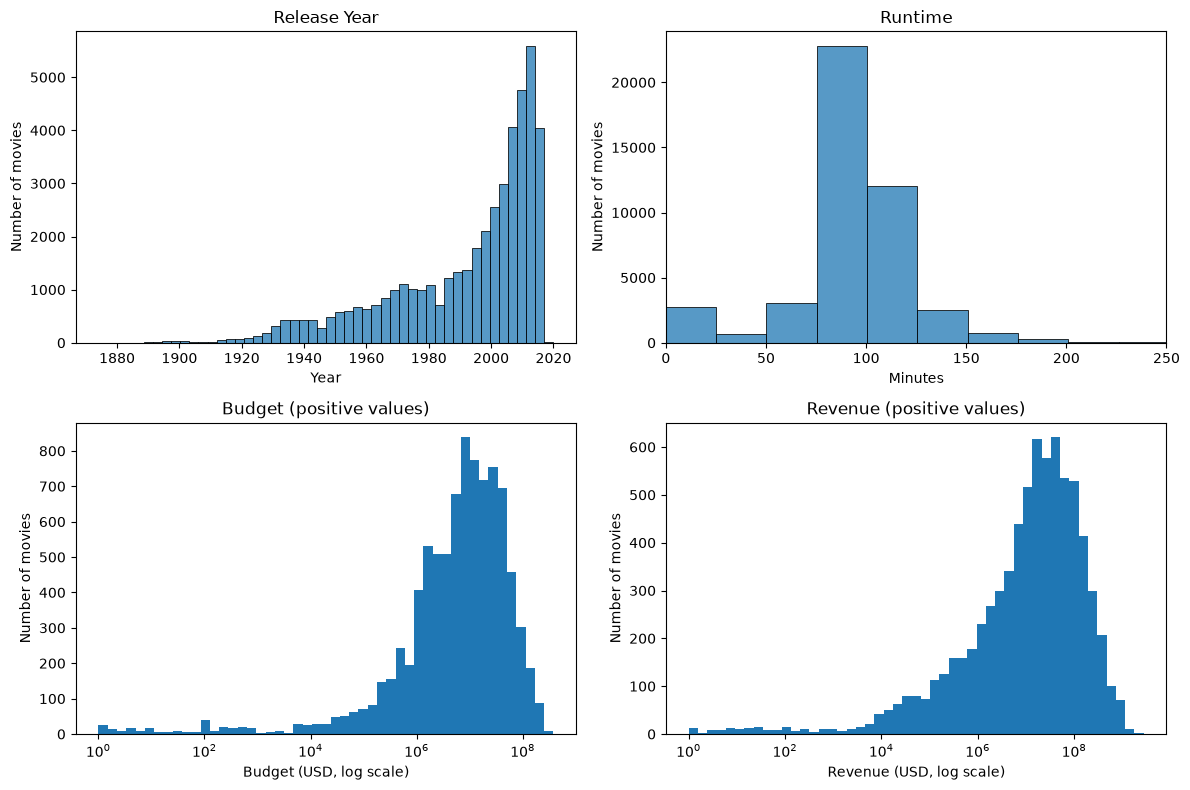

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Release year
sns.histplot(
    data=metadata_eda,
    x="release_year",
    bins=50,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Release Year")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Number of movies")

# Runtime
sns.histplot(
    data=metadata_eda,
    x="runtime",
    bins=50,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Runtime")
axes[0, 1].set_xlabel("Minutes")
axes[0, 1].set_ylabel("Number of movies")
axes[0, 1].set_xlim(0, 250)

# Budget: positive values with logarithmic bins
positive_budget = metadata_eda.loc[
    metadata_eda["budget"] > 0, "budget"
]

if not positive_budget.empty:
    budget_bins = np.logspace(
        np.log10(positive_budget.min()),
        np.log10(positive_budget.max()),
        50
    )

    axes[1, 0].hist(positive_budget, bins=budget_bins)
    axes[1, 0].set_xscale("log")

axes[1, 0].set_title("Budget (positive values)")
axes[1, 0].set_xlabel("Budget (USD, log scale)")
axes[1, 0].set_ylabel("Number of movies")

# Revenue: positive values with logarithmic bins
positive_revenue = metadata_eda.loc[
    metadata_eda["revenue"] > 0, "revenue"
]

if not positive_revenue.empty:
    revenue_bins = np.logspace(
        np.log10(positive_revenue.min()),
        np.log10(positive_revenue.max()),
        50
    )

    axes[1, 1].hist(positive_revenue, bins=revenue_bins)
    axes[1, 1].set_xscale("log")

axes[1, 1].set_title("Revenue (positive values)")
axes[1, 1].set_xlabel("Revenue (USD, log scale)")
axes[1, 1].set_ylabel("Number of movies")

plt.tight_layout()
plt.show()

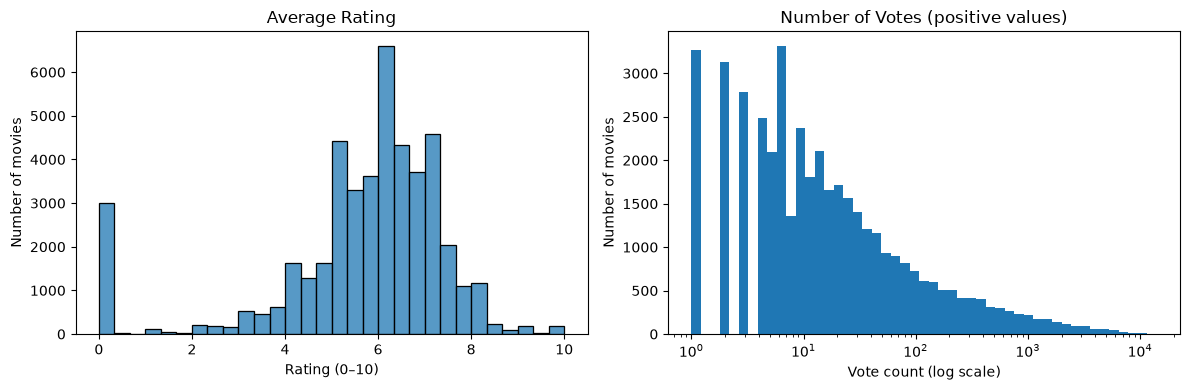

Movies with zero votes: 2899


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Average rating
sns.histplot(
    data=metadata_eda,
    x="vote_average",
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Average Rating")
axes[0].set_xlabel("Rating (0–10)")
axes[0].set_ylabel("Number of movies")

# Positive vote counts
positive_votes = metadata_eda.loc[
    metadata_eda["vote_count"] > 0, "vote_count"
]

if not positive_votes.empty:
    vote_bins = np.logspace(
        np.log10(positive_votes.min()),
        np.log10(positive_votes.max()),
        50
    )

    axes[1].hist(positive_votes, bins=vote_bins)
    axes[1].set_xscale("log")

axes[1].set_title("Number of Votes (positive values)")
axes[1].set_xlabel("Vote count (log scale)")
axes[1].set_ylabel("Number of movies")

plt.tight_layout()
plt.show()

print(
    "Movies with zero votes:",
    metadata_eda["vote_count"].eq(0).sum()
)

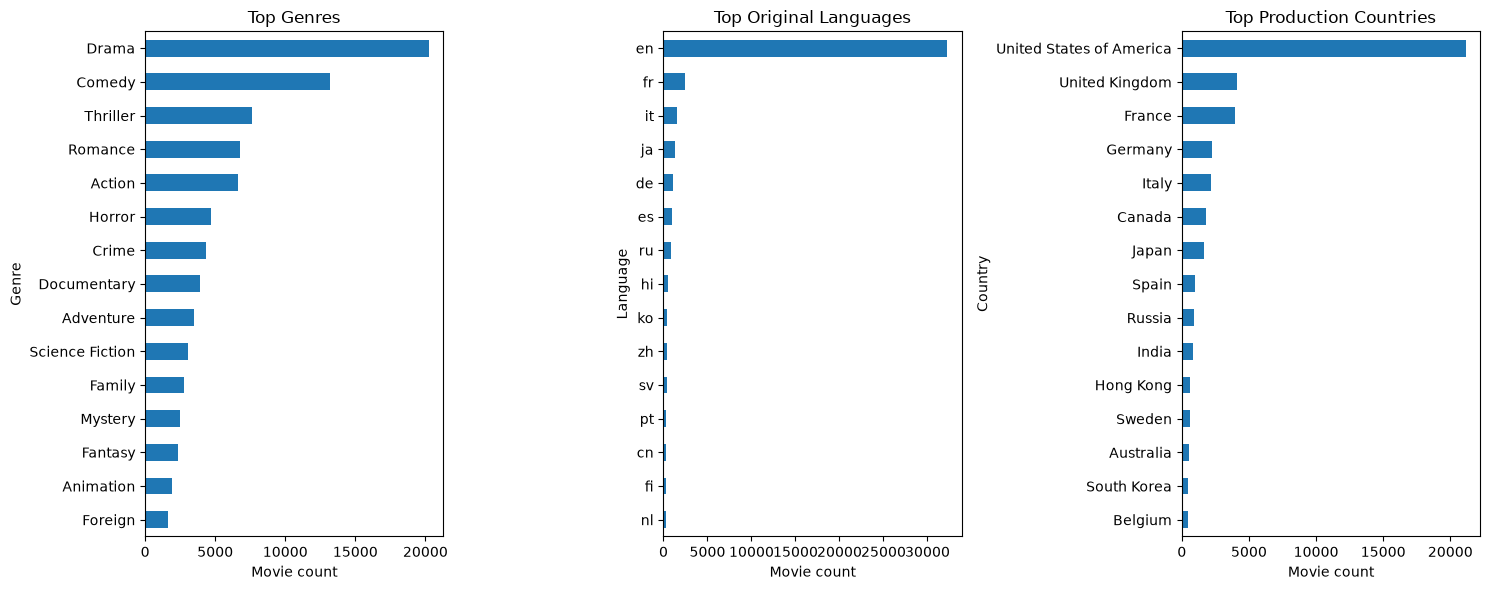

In [14]:
def extract_names(value):
    if not isinstance(value, list):
        return []

    return [
        item["name"]
        for item in value
        if isinstance(item, dict) and item.get("name")
    ]


genre_counts = (
    metadata_eda["genres"]
    .apply(extract_names)
    .explode()
    .dropna()
    .value_counts()
)

language_counts = (
    metadata_eda["original_language"]
    .fillna("Missing")
    .replace("", "Missing")
    .value_counts()
)

country_counts = (
    metadata_eda["production_countries"]
    .apply(extract_names)
    .explode()
    .dropna()
    .value_counts()
)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

genre_counts.head(15).sort_values().plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Top Genres")
axes[0].set_xlabel("Movie count")
axes[0].set_ylabel("Genre")

language_counts.head(15).sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Top Original Languages")
axes[1].set_xlabel("Movie count")
axes[1].set_ylabel("Language")

country_counts.head(15).sort_values().plot(
    kind="barh", ax=axes[2]
)
axes[2].set_title("Top Production Countries")
axes[2].set_xlabel("Movie count")
axes[2].set_ylabel("Country")

plt.tight_layout()
plt.show()

In [15]:
has_collection = metadata_eda["belongs_to_collection"].apply(
    lambda value: (
        isinstance(value, dict)
        and bool(value.get("name"))
    )
)

collection_names = metadata_eda.loc[
    has_collection, "belongs_to_collection"
].apply(lambda value: value["name"])

collection_summary = pd.Series({
    "Total movies": len(metadata_eda),
    "Movies with a collection": int(has_collection.sum()),
    "Movies without a collection": int((~has_collection).sum()),
    "Percentage with a collection": round(
        has_collection.mean() * 100, 2
    ),
    "Distinct collection names": collection_names.nunique()
})

display(collection_summary.to_frame("Value"))

,Value
Total movies,45466.00
Movies with a collection,4491.00
Movies without a collection,40975.00
Percentage with a collection,9.88
Distinct collection names,1695.00


## 5. Check relationships between files
Ensure you can combine the data correctly for Part 2.

In [16]:
print(movies["id"].dtypes)
movie_ids_num = pd.to_numeric(movies["id"], errors="coerce").dropna().astype(int).drop_duplicates()
credit_ids = credits["id"].drop_duplicates()
keyword_ids = keywords["id"].drop_duplicates()
print("Unique ids in movies_metadata:", len(movie_ids_num))
print("Unique ids in credits:", len(credit_ids))
print("Unique ids in keywords:", len(keyword_ids))

ids_in_movies_not_in_credits = movie_ids_num[~movie_ids_num.isin(credit_ids)]
ids_in_movies_not_in_keywords = movie_ids_num[~movie_ids_num.isin(keyword_ids)]
ids_in_credits_not_in_movies = credit_ids[~credit_ids.isin(movie_ids_num)]
ids_in_keywords_not_in_movies = keyword_ids[~keyword_ids.isin(movie_ids_num)]

print("Ids in movies_metadata but not in credits:", len(ids_in_movies_not_in_credits))
display(movies.loc[ids_in_movies_not_in_credits.index, ["id", "title"]].head())
print("Ids in credits but not in movies_metadata:", len(ids_in_credits_not_in_movies))
print("Ids in movies_metadata but not in keywords:", len(ids_in_movies_not_in_keywords))
display(movies.loc[ids_in_movies_not_in_keywords.index, ["id", "title"]].head())
print("Ids in keywords but not in movies_metadata:", len(ids_in_keywords_not_in_movies))
print("Credits and keywords datasets have the same ids:", set(credit_ids) == set(keyword_ids))


str
Unique ids in movies_metadata: 45433
Unique ids in credits: 45432
Unique ids in keywords: 45432
Ids in movies_metadata but not in credits: 1


,id,title
42883,401840,School's out


Ids in credits but not in movies_metadata: 0
Ids in movies_metadata but not in keywords: 1


,id,title
42883,401840,School's out


Ids in keywords but not in movies_metadata: 0
Credits and keywords datasets have the same ids: True


In [17]:
print(links.dtypes)
display(links.head())
tmdb_ids = links["tmdbId"].dropna().astype(int).drop_duplicates()
imdb_ids = ("tt" + links["imdbId"].astype(str).str.zfill(7)).drop_duplicates()
print("Rows in links dataset:", len(links))
print("Missing imdbId:", links["imdbId"].isna().sum())
print("Missing tmdbId:", links["tmdbId"].isna().sum())
print("Duplicate movieIds:", links["movieId"].duplicated().sum())
print("Duplicate imdbIds:", links["imdbId"].dropna().duplicated().sum())
print("Duplicate tmdbIds:", links["tmdbId"].dropna().duplicated().sum())
tmdb_ids_not_in_movies = tmdb_ids[~tmdb_ids.isin(movie_ids_num)]
imdb_ids_not_in_movies = imdb_ids[~imdb_ids.isin(movies["imdb_id"])]
print("tmdbIds in links but not in movies_metadata:", len(tmdb_ids_not_in_movies))
display(links[links["tmdbId"].isin(tmdb_ids_not_in_movies)].head(10))
print("imdbIds in links but not in movies_metadata:", len(imdb_ids_not_in_movies))
display(links[("tt" + links["imdbId"].astype(str).str.zfill(7)).isin(imdb_ids_not_in_movies)].head(10))


movieId      int64
imdbId       int64
tmdbId     float64
dtype: object


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


Rows in links dataset: 45843
Missing imdbId: 0
Missing tmdbId: 219
Duplicate movieIds: 0
Duplicate imdbIds: 0
Duplicate tmdbIds: 30
tmdbIds in links but not in movies_metadata: 161


,movieId,imdbId,tmdbId
4114,4207,100232,12773.0
4474,4568,96913,17882.0
4974,5069,270933,68149.0
5113,5209,81809,24549.0
7416,7669,112130,164721.0
8812,26379,75520,2413.0
8855,26452,83387,82205.0
8973,26649,96639,13057.0
8994,26693,99864,2670.0
9187,27049,135659,15738.0


imdbIds in links but not in movies_metadata: 490


,movieId,imdbId,tmdbId
140,142,94878,NaN
598,604,115978,NaN
708,720,118114,NaN
709,721,114103,NaN
711,723,92123,131232.0
718,730,125877,NaN
756,769,116992,NaN
757,770,38426,NaN
778,791,113610,NaN
806,821,112746,NaN


In [18]:
print(ratings.dtypes)
display(ratings.head(3))
print("Rows in ratings dataset:", len(ratings))
print("Unique userIds:", ratings["userId"].nunique())
print("Unique movieIds:", ratings["movieId"].nunique())

movie_ids_in_ratings = ratings["movieId"].drop_duplicates()
movie_ids_in_rating_not_in_links = movie_ids_in_ratings[~movie_ids_in_ratings.isin(links["movieId"])]
print("Movie ids in ratings but not in links:", len(movie_ids_in_rating_not_in_links))

movieid_to_tmdbid = links.set_index("movieId")["tmdbId"]
ratings_tmdbids = ratings["movieId"].map(movieid_to_tmdbid)
ratings_tmdbids_in_movies = ratings_tmdbids.isin(movie_ids_num)
not_mapped_ratings = (~ratings_tmdbids_in_movies).sum()
not_mapped_ratings_percent = round((~ratings_tmdbids_in_movies).mean() * 100, 2)
print("Ratings that can be mapped to movies_metadata:", ratings_tmdbids_in_movies.sum())
print(f"Ratings that cannot be mapped to movies_metadata: {not_mapped_ratings} ({not_mapped_ratings_percent}%)")


userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object


,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523


Rows in ratings dataset: 26024289
Unique userIds: 270896
Unique movieIds: 45115
Movie ids in ratings but not in links: 0
Ratings that can be mapped to movies_metadata: 25981582
Ratings that cannot be mapped to movies_metadata: 42707 (0.16%)


In [19]:
rated_tmdb_ids = ratings_tmdbids.dropna().astype(int).drop_duplicates()
movies_without_ratings = movie_ids_num[~movie_ids_num.isin(rated_tmdb_ids)]
percent = round(len(movies_without_ratings) / len(movie_ids_num) * 100, 2)
print(f"Movies in movies_metadata without ratings: {len(movies_without_ratings)} ({percent}%)")

Movies in movies_metadata without ratings: 722 (1.59%)


## 6. Investigate ratings and cast/crew data

Prepare for the assignment's aggregation questions.

In [16]:
# 6.1 Ratings analysis
ratings_df = pd.read_csv(DATA_DIR / "ratings_small.csv")

print("Dataset shape:", ratings_df.shape)

display(
    ratings_df.head()
    .style
    .set_caption("First five rows of ratings_small.csv")
)

display(
    ratings_df["rating"]
    .describe()
    .rename_axis(None)
    .to_frame(name="Value")
    .style
    .set_caption("Summary statistics for ratings")
    .format("{:.2f}")
)

display(
    ratings_df["rating"]
    .value_counts()
    .sort_index()
    .rename_axis(None)
    .to_frame(name="Number of ratings")
    .style
    .set_caption("Distribution of rating values")
    .format("{:.0f}")
)

ratings_per_user = ratings_df.groupby("userId").size()

display(
    ratings_per_user
    .describe()
    .rename_axis(None)
    .to_frame(name="Number of ratings")
    .style
    .set_caption("Summary statistics for ratings per user")
    .format("{:.2f}")
)

ratings_df["rating_date"] = pd.to_datetime(
    ratings_df["timestamp"],
    unit="s",
    errors="coerce"
)

timestamp_summary = pd.DataFrame({
    "Value": [
        ratings_df["rating_date"].min(),
        ratings_df["rating_date"].max(),
        ratings_df["rating_date"].isna().sum()
    ]
}, index=[
    "Earliest timestamp",
    "Latest timestamp",
    "Invalid timestamps"
])

display(
    timestamp_summary
    .rename_axis(None)
    .style
    .set_caption("Rating timestamp summary")
)

valid_ratings = (
    ratings_df["rating"].between(0.5, 5.0)
    & (ratings_df["rating"] * 2 % 1 == 0)
)

rating_validation = pd.DataFrame({
    "Count": [
        valid_ratings.sum(),
        (~valid_ratings).sum()
    ]
}, index=[
    "Valid ratings",
    "Invalid ratings"
])

display(
    rating_validation
    .rename_axis(None)
    .style
    .set_caption("Rating value validation")
    .format("{:.0f}")
)

Dataset shape: (100004, 4)


,userId,movieId,rating,timestamp
0,1,31,2.500000,1260759144
1,1,1029,3.000000,1260759179
2,1,1061,3.000000,1260759182
3,1,1129,2.000000,1260759185
4,1,1172,4.000000,1260759205


,Value
count,100004.00
mean,3.54
std,1.06
min,0.50
25%,3.00
50%,4.00
75%,4.00
max,5.00


,Number of ratings
0.500000,1101
1.000000,3326
1.500000,1687
2.000000,7271
2.500000,4449
3.000000,20064
3.500000,10538
4.000000,28750
4.500000,7723
5.000000,15095


,Number of ratings
count,671.00
mean,149.04
std,231.23
min,20.00
25%,37.00
50%,71.00
75%,161.00
max,2391.00


,Value
Earliest timestamp,1995-01-09 11:46:49
Latest timestamp,2016-10-16 17:57:24
Invalid timestamps,0


,Count
Valid ratings,100004
Invalid ratings,0


In [17]:
# 6.2 Cast analysis
parsed_credits = parsed_data["credits"].copy()

def get_cast(value):
    return value if isinstance(value, list) else []

parsed_credits["cast_list"] = parsed_credits["cast"].apply(get_cast)
parsed_credits["cast_size"] = parsed_credits["cast_list"].apply(len)

display(
    parsed_credits["cast_size"]
    .describe()
    .rename_axis(None)
    .to_frame(name="Cast members per movie")
    .style
    .set_caption("Summary statistics for cast size")
    .format("{:.2f}")
)

cast_records = []

for _, row in parsed_credits.iterrows():
    for member in row["cast_list"]:
        if isinstance(member, dict):
            cast_records.append({
                "movie_id": row["id"],
                "actor_id": member.get("id"),
                "actor_name": member.get("name"),
                "gender": member.get("gender"),
                "order": member.get("order")
            })

cast_df = pd.DataFrame(cast_records)

print("Number of cast credits:", len(cast_df))

if not cast_df.empty:
    cast_df["order"] = pd.to_numeric(
        cast_df["order"],
        errors="coerce"
    )

    display(
        cast_df["order"]
        .describe()
        .rename_axis(None)
        .to_frame(name="Cast order")
        .style
        .set_caption("Summary statistics for cast order")
        .format("{:.2f}")
    )

if not cast_df.empty:
    gender_labels = {
        0: "Unknown / unspecified (0)",
        1: "Female (1)",
        2: "Male (2)"
    }

    cast_df["gender_label"] = (
        pd.to_numeric(cast_df["gender"], errors="coerce")
        .map(gender_labels)
        .fillna("Other / missing")
    )

    gender_distribution = (
        cast_df["gender_label"]
        .value_counts()
        .rename_axis(None)
        .to_frame(name="Number of cast credits")
    )

    gender_distribution["Percentage"] = (
        gender_distribution["Number of cast credits"]
        / len(cast_df)
        * 100
    )

    display(
        gender_distribution
        .style
        .set_caption("Gender distribution among cast credits")
        .format({
            "Number of cast credits": "{:,.0f}",
            "Percentage": "{:.2f}%"
        })
    )

if not cast_df.empty:
    actor_movie_credits = (
        cast_df.dropna(subset=["actor_id"])
        .drop_duplicates(subset=["movie_id", "actor_id"])
    )

    movies_per_actor = (
        actor_movie_credits
        .groupby(["actor_id", "actor_name"], dropna=False)["movie_id"]
        .nunique()
        .rename("Credited movies")
        .reset_index()
        .sort_values("Credited movies", ascending=False)
    )

    display(
        movies_per_actor["Credited movies"]
        .describe()
        .rename_axis(None)
        .to_frame(name="Credited movies per actor")
        .style
        .set_caption("Summary statistics for credited movies per actor")
        .format("{:.2f}")
    )

    display(
        movies_per_actor.head(10)[["actor_name", "Credited movies"]]
        .reset_index(drop=True)
        .style
        .hide(axis="index")
        .set_caption("Top 10 actors by number of credited movies")
        .format({"Credited movies": "{:,.0f}"})
    )

,Cast members per movie
count,45476.00
mean,12.37
std,12.09
min,0.00
25%,6.00
50%,10.00
75%,15.00
max,313.00


Number of cast credits: 562474


,Cast order
count,562474.00
mean,11.85
std,16.01
min,0.00
25%,3.00
50%,7.00
75%,14.00
max,313.00


,Number of cast credits,Percentage
Male (2),"226,713",40.31%
Unknown / unspecified (0),"223,964",39.82%
Female (1),"111,797",19.88%


,Credited movies per actor
count,206172.00
mean,2.72
std,5.25
min,1.00
25%,1.00
50%,1.00
75%,2.00
max,240.00


actor_name,Credited movies
Bess Flowers,240
Christopher Lee,148
John Wayne,125
Samuel L. Jackson,123
Michael Caine,110
Gérard Depardieu,110
John Carradine,109
Jackie Chan,108
Donald Sutherland,108
Frank Welker,104


In [18]:
# 6.3 Crew analysis
parsed_crew = parsed_data["credits"].copy()

def get_crew(value):
    return value if isinstance(value, list) else []

parsed_crew["crew_list"] = parsed_crew["crew"].apply(get_crew)
parsed_crew["crew_size"] = parsed_crew["crew_list"].apply(len)

display(
    parsed_crew["crew_size"]
    .describe()
    .rename_axis(None)
    .to_frame(name="Crew members per movie")
    .style
    .set_caption("Summary statistics for crew size")
    .format("{:.2f}")
)

crew_records = []

for _, row in parsed_crew.iterrows():
    for member in row["crew_list"]:
        if isinstance(member, dict):
            crew_records.append({
                "movie_id": row["id"],
                "person_id": member.get("id"),
                "person_name": member.get("name"),
                "department": member.get("department"),
                "job": member.get("job"),
                "gender": member.get("gender")
            })

crew_df = pd.DataFrame(crew_records)

if not crew_df.empty:
    department_counts = (
        crew_df["department"]
        .fillna("Unknown / missing")
        .value_counts()
        .rename_axis(None)
        .to_frame(name="Number of crew credits")
    )

    display(
        department_counts.head(10)
        .style
        .set_caption("Top 10 crew departments by number of credits")
        .format("{:,.0f}")
    )

if not crew_df.empty:
    job_counts = (
        crew_df["job"]
        .fillna("Unknown / missing")
        .value_counts()
        .rename_axis(None)
        .to_frame(name="Number of crew credits")
    )

    display(
        job_counts.head(10)
        .style
        .set_caption("Top 10 crew jobs by number of credits")
        .format("{:,.0f}")
    )

if not crew_df.empty:
    directors_df = crew_df[crew_df["job"] == "Director"].copy()

    director_movie_credits = (
        directors_df.dropna(subset=["person_id"])
        .drop_duplicates(subset=["movie_id", "person_id"])
    )

    movies_per_director = (
        director_movie_credits
        .groupby(["person_id", "person_name"])["movie_id"]
        .nunique()
        .rename("Credited movies")
        .reset_index()
        .sort_values("Credited movies", ascending=False)
    )

    display(
        movies_per_director.head(10)[["person_name", "Credited movies"]]
        .reset_index(drop=True)
        .style
        .hide(axis="index")
        .set_caption("Top 10 directors by number of credited movies")
        .format({"Credited movies": "{:,.0f}"})
    )

,Crew members per movie
count,45476.00
mean,10.21
std,15.80
min,0.00
25%,2.00
50%,6.00
75%,12.00
max,435.00


,Number of crew credits
Production,"94,498"
Writing,"74,831"
Directing,"58,134"
Sound,"50,605"
Art,"40,694"
Camera,"33,539"
Crew,"31,605"
Costume & Make-Up,"30,850"
Editing,"29,831"
Visual Effects,"14,861"


,Number of crew credits
Director,"49,048"
Producer,"43,555"
Writer,"30,431"
Screenplay,"25,163"
Editor,"23,800"
Director of Photography,"20,659"
Executive Producer,"18,866"
Original Music Composer,"15,790"
Casting,"12,635"
Art Direction,"11,689"


person_name,Credited movies
John Ford,68
Michael Curtiz,65
Werner Herzog,55
Alfred Hitchcock,53
Georges Méliès,51
Jean-Luc Godard,50
Woody Allen,49
Sidney Lumet,46
Charlie Chaplin,44
William A. Wellman,43


In [19]:
# 6.4 Metadata fields for assignment queries
metadata_df = parsed_data["metadata"].copy()

metadata_df["release_date_parsed"] = pd.to_datetime(
    metadata_df["release_date"],
    errors="coerce"
)

metadata_df["release_year"] = metadata_df["release_date_parsed"].dt.year

metadata_df["release_decade"] = (
    (metadata_df["release_year"] // 10) * 10
).astype("Int64")

def get_primary_genre(value):
    if isinstance(value, list) and value:
        first_genre = value[0]
        if isinstance(first_genre, dict):
            return first_genre.get("name")
    return None

metadata_df["primary_genre"] = metadata_df["genres"].apply(
    get_primary_genre
)

decade_genre_summary = pd.DataFrame({
    "Value": [
        metadata_df["release_year"].notna().sum(),
        metadata_df["release_decade"].nunique(),
        metadata_df["primary_genre"].nunique(),
        metadata_df["primary_genre"].isna().sum()
    ]
}, index=[
    "Movies with a valid release year",
    "Distinct release decades",
    "Distinct primary genres",
    "Movies without a primary genre"
])

display(
    decade_genre_summary
    .rename_axis(None)
    .style
    .set_caption("Release year and primary genre overview")
)

genre_counts = []

for genres in metadata_df["genres"]:
    if isinstance(genres, list):
        genre_counts.append(len({
            genre.get("name")
            for genre in genres
            if isinstance(genre, dict) and genre.get("name")
        }))
    else:
        genre_counts.append(0)

metadata_df["genre_count"] = genre_counts

display(
    metadata_df["genre_count"]
    .describe()
    .rename_axis(None)
    .to_frame(name="Genres per movie")
    .style
    .set_caption("Summary statistics for genres per movie")
    .format("{:.2f}")
)

text_field_summary = pd.DataFrame({
    "Non-empty records": [
        metadata_df["overview"].fillna("").astype(str).str.strip().ne("").sum(),
        metadata_df["tagline"].fillna("").astype(str).str.strip().ne("").sum()
    ],
    "Empty records": [
        metadata_df["overview"].fillna("").astype(str).str.strip().eq("").sum(),
        metadata_df["tagline"].fillna("").astype(str).str.strip().eq("").sum()
    ]
}, index=["Overview", "Tagline"])

display(
    text_field_summary
    .rename_axis(None)
    .style
    .set_caption("Text-field availability for movie search")
    .format("{:,.0f}")
)

,Value
Movies with a valid release year,45376
Distinct release decades,16
Distinct primary genres,23
Movies without a primary genre,2442


,Genres per movie
count,45466.00
mean,2.00
std,1.13
min,0.00
25%,1.00
50%,2.00
75%,3.00
max,8.00


,Non-empty records,Empty records
Overview,"44,507",959
Tagline,"20,411","25,055"
